# Leaderboard Best (0.95836)

In [ ]:
import lightgbm as lgb
import xgboost as xgb
import torch, torch.nn as nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random, time
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score,precision_score, recall_score
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
edges = pd.read_csv("txs_edgelist.csv")
print(train.shape, test.shape, edges.shape)

print(train["label"].value_counts(dropna=False))
n_labeled = train["label"].isin([0, 1]).sum()
print(n_labeled, "labeled out of", len(train))
#drop unlabelled rows, assign labels as integers
lab_train = train[train["label"].isin([0,1])].copy()
lab_train["label"]=lab_train["label"].astype(int)
print(lab_train.shape)

(141772, 168) (15329, 168) (234355, 2)
label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64
31235 labeled out of 141772
(31235, 168)


In [3]:
ids = set(train.txId) | set(test.txId)
nodes = set(edges.iloc[:, 0]) | set(edges.iloc[:, 1])
print("distinct txIds in edges:", len(nodes))
print("edge txIds in neither file:", len(nodes - ids))

step = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]]).set_index("txId").time_step
e = edges.copy(); e.columns = ["src", "dst"]
e["s1"], e["s2"] = e.src.map(step), e.dst.map(step)
both = e.dropna(subset=["s1", "s2"])
print("edges with both ends known:", len(both))
print("edges crossing time steps:", (both.s1 != both.s2).sum())

distinct txIds in edges: 203769
edge txIds in neither file: 46668
edges with both ends known: 175918
edges crossing time steps: 0


In [4]:
#find features that behave like hidden `time_step` feature
feats= [col for col in lab_train.columns if col.startswith("feat_")]
corr = lab_train[feats].corrwith(lab_train["time_step"], method="spearman").abs()
print(corr.sort_values(ascending=False).head(10))
time_corr = corr[corr> 0.9].index.tolist()
print(time_corr)

feat_101    0.997740
feat_136    0.992577
feat_103    0.989650
feat_100    0.982792
feat_139    0.958704
feat_137    0.910372
feat_106    0.515594
feat_2      0.515558
feat_142    0.478613
feat_109    0.461951
dtype: float64
['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_137', 'feat_139']


I excluded `time_step` and correlated features since test set is set in the future so these features that encodes when or time-related transaction info is not a stable signal. Time is also not a cause for fraud and exlcuding it prevents the model from leaning on it and finding patterns that cannot be reproduced in the test set, which affects performance. By exluding it and similar features, the model has to learn time-invariant patterns 

## Find univariate AUC score of each feature for relative importance

In [5]:
time_corr = ["feat_100","feat_101", "feat_103", "feat_136", "feat_137", "feat_139"]
BASE  = [c for c in feats if c not in time_corr]#gives 156 original cols
y_lab = lab_train.set_index("txId")["label"].astype(int)
X_lab = lab_train.set_index("txId")[BASE]# 159 raw columns, drift columns already excluded
uni_auc = {}
for c in BASE:
    auc = roc_auc_score(y_lab, X_lab[c])
    uni_auc[c] = max(auc, 1-auc)#AUC= 1.0 & AUC=0.0 is just as useful as a predictor of fraud
uni_auc = pd.Series(uni_auc).sort_values(ascending=False)
print(uni_auc.head(50))
#deduplicate AUC features
AGG50 = uni_auc.head(50).index.tolist()

feat_53     0.856809
feat_55     0.839660
feat_90     0.836702
feat_5      0.817001
feat_14     0.816922
feat_66     0.816405
feat_60     0.816392
feat_29     0.813166
feat_23     0.813159
feat_132    0.810787
feat_41     0.806712
feat_47     0.806523
feat_142    0.801188
feat_49     0.797255
feat_43     0.797206
feat_89     0.793743
feat_25     0.791837
feat_31     0.791837
feat_18     0.777795
feat_91     0.766406
feat_156    0.764950
feat_138    0.758154
feat_144    0.753163
feat_161    0.750151
feat_30     0.748707
feat_24     0.748704
feat_10     0.745401
feat_54     0.744100
feat_96     0.741619
feat_4      0.741365
feat_84     0.740558
feat_6      0.735915
feat_78     0.732345
feat_163    0.729555
feat_76     0.729163
feat_58     0.719503
feat_52     0.718325
feat_64     0.717487
feat_130    0.715689
feat_42     0.715289
feat_48     0.715113
feat_83     0.706498
feat_119    0.705780
feat_95     0.696980
feat_154    0.694913
feat_121    0.694634
feat_85     0.694294
feat_46     0

# Selection of model by comparing AUC on 159 raw features

159 features | 31235 labelled rows


C:\Users\chail\AppData\Local\Temp\ipykernel_41060\618106025.py:85: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .assign(label=pd.to_numeric(train["label"], errors="coerce"))
C:\Users\chail\AppData\Local\Temp\ipykernel_41060\618106025.py:104: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(np.vstack([rows, cols]), vals, (n, n)).coalesce()


,ROC AUC,Accuracy,Precision,Recall,F1,Fold 3 AUC
LightGBM,0.8850,0.9369,0.9712,0.6461,0.7753,0.8774
XGBoost,0.8595,0.9342,0.9627,0.6367,0.7659,0.8712
FNN,0.8563,0.8765,0.7170,0.4115,0.4993,0.8420
CNN,0.8317,0.8949,0.8136,0.4971,0.6135,0.8231
Logistic regression,0.8151,0.8474,0.5623,0.5115,0.5110,0.8005
GCN(graph NN),0.8129,0.8602,0.6042,0.5103,0.5427,0.8064
Random Forest,0.8006,0.9385,0.9831,0.6470,0.7798,0.7952


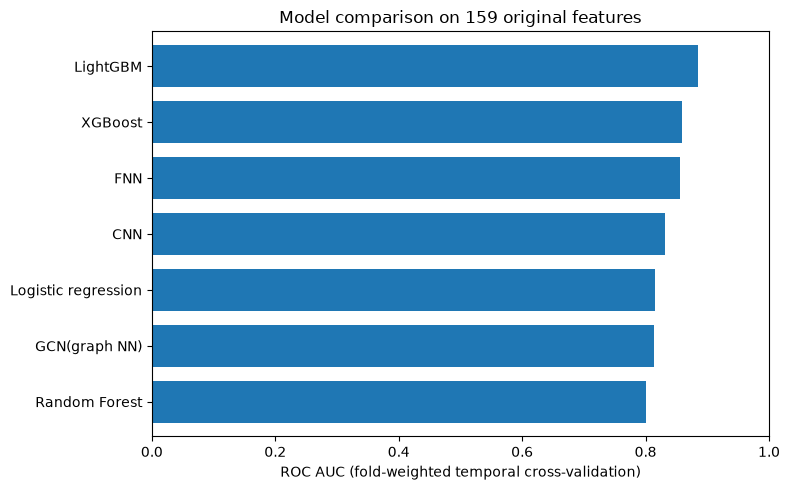

In [6]:
print(len(BASE), "features |", len(lab_train), "labelled rows")
FOLDS = [((1,14), (18,31)), ((1,17), (21,34)), ((1,21), (25,35))]# temp CV of 3 folds for train and validation steps
WEIGHTS = np.array([0.2, 0.3, 0.5])# fold 3 is closest to the real test period
SEEDS = (0, 1)
early_stop = 3# neural nets hold back the last 3 training steps for early stopping
THRESHOLD = 0.5 #cut-off point

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
#Neural network building blocks
#Feed-fwd network (FNN) w 1 hidden layer w dropout
class SimpleFraudMLPWithDropout(nn.Module):
    def __init__(self, input_size, hidden_size=1000, p=0.2):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p)
        self.fc2 = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return self.sigmoid(self.fc2(self.dropout(self.relu(self.fc1(x)))))
#CNN with 1D layer, each row is feature vector
class FraudCNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2, 2)
        self.flat = 32 * (input_size // 2 // 2)# 159 -> 79 -> 39 after two pools
        self.fc1 = nn.Linear(self.flat, 64)
        self.fc2 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = x.unsqueeze(1)# (B, F) -> (B, 1, F)
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = torch.relu(self.fc1(x.view(-1, self.flat)))
        return self.sigmoid(self.fc2(x))

class EarlyStopping:
    def __init__(self, patience=2):
        self.patience, self.counter, self.best = patience, 0, np.inf
    def continue_training(self, loss):
        if loss < self.best:
            self.best, self.counter = loss, 0
        else:
            self.counter += 1
        return self.counter <= self.patience

def evaluate_loss(model, loader, criterion):
    model.eval()
    with torch.no_grad():
        return np.mean([criterion(model(x).squeeze(1), y).item() for x, y in loader])
#train on early training steps & stops on last early_stop train step
def nn_fit_predict(build, s, seed, max_epochs=100, patience=2, lr=0.0005):
    set_seed(seed)
    inner = s["steps"] <= s["a"][1] - early_stop
    to_t = lambda arr: torch.FloatTensor(np.asarray(arr, dtype=np.float32))
    train_loader = DataLoader(TensorDataset(to_t(s["Xtr"][inner]), to_t(s["ytr"][inner])),
                              batch_size=256, shuffle=True)
    es_loader = DataLoader(TensorDataset(to_t(s["Xtr"][~inner]), to_t(s["ytr"][~inner])), batch_size=256)
    model = build(s["Xtr"].shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion, stopper = nn.BCELoss(), EarlyStopping(patience)
    for _ in range(max_epochs):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            criterion(model(x).squeeze(1), y).backward()
            optimizer.step()
        if not stopper.continue_training(evaluate_loss(model, es_loader, criterion)):
            break
    model.eval()
    with torch.no_grad():
        return model(to_t(s["Xva"])).squeeze(1).numpy()
#2 layer graph neural network 
E1, E2 = edges.columns[:2]
_ADJ_CACHE = {}
# every training transaction (labelled or not) with its 159 raw features; label is NaN if unlabelled
train_nodes = (train[["txId", "time_step"] + BASE]
               .assign(label=pd.to_numeric(train["label"], errors="coerce"))
               .reset_index(drop=True))
class GCN(nn.Module):
    """Each layer mixes a node's features with its neighbours'."""
    def __init__(self, d, hidden=64, p=0.3):
        super().__init__()
        self.l1, self.l2, self.drop = nn.Linear(d, hidden), nn.Linear(hidden, 1), nn.Dropout(p)
    def forward(self, A, X):
        h = self.drop(torch.relu(torch.sparse.mm(A, self.l1(X))))
        return torch.sparse.mm(A, self.l2(h)).squeeze(1)

def normalised_adjacency(ids):
    """Symmetric normalised adjacency with self-loops: D^-1/2 (A + I) D^-1/2."""
    pos = pd.Series(np.arange(len(ids)), index=ids)
    e = edges[edges[E1].isin(pos.index) & edges[E2].isin(pos.index)]
    r, c, n = pos[e[E1]].values, pos[e[E2]].values, len(ids)
    rows, cols = np.r_[r, c, np.arange(n)], np.r_[c, r, np.arange(n)]
    deg = np.bincount(rows, minlength=n).astype(np.float32)
    vals = (1 / np.sqrt(deg[rows] * deg[cols])).astype(np.float32)
    return torch.sparse_coo_tensor(np.vstack([rows, cols]), vals, (n, n)).coalesce()


def fit_gcn(s, seed, epochs=300, patience=20):
    """Graph = every training transaction up to the end of the validation window.
    No edge crosses a time step, so validation nodes never pass messages to training nodes."""
    a, b = s["a"], s["b"]
    set_seed(seed)
    nodes = train_nodes[train_nodes.time_step <= b[1]].reset_index(drop=True)
    if b[1] not in _ADJ_CACHE:
        _ADJ_CACHE[b[1]] = normalised_adjacency(nodes.txId.values)
    A = _ADJ_CACHE[b[1]]

    sc = StandardScaler().fit(nodes.loc[nodes.time_step <= a[1], BASE])   # fit on training steps only
    X = torch.FloatTensor(np.nan_to_num(sc.transform(nodes[BASE])).astype(np.float32))
    labelled = nodes.label.isin([0, 1]).values
    y = torch.FloatTensor(nodes.label.fillna(0).to_numpy(np.float32))
    fit_mask = torch.tensor(labelled & nodes.time_step.between(a[0], a[1] - early_stop).values)
    es_mask = torch.tensor(labelled & nodes.time_step.between(a[1] - early_stop + 1, a[1]).values)
    va_mask = labelled & nodes.time_step.between(*b).values

    model = GCN(X.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    criterion = nn.BCEWithLogitsLoss()
    best, wait, best_state = np.inf, 0, None
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        criterion(model(A, X)[fit_mask], y[fit_mask]).backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            loss = criterion(model(A, X)[es_mask], y[es_mask]).item()
        if loss < best:
            best, wait, best_state = loss, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait > patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(A, X)).numpy()
    return pd.Series(p[va_mask], index=nodes.txId.values[va_mask]).reindex(s["va_ids"]).to_numpy()
#lightGBM
def fit_lightgbm(s, seed):
    params = {"objective": "binary", "learning_rate": 0.1, "verbose": -1, "seed": seed,
              "bagging_fraction": 0.75, "bagging_freq": 1, "feature_fraction": 0.9}
    return lgb.train(params, lgb.Dataset(s["Xtr"], label=s["ytr"]), num_boost_round=100).predict(s["Xva"])

#Total model comaprison with untuned default params
MODELS = {
    "Logistic regression": ("scaled", lambda s, sd: LogisticRegression(max_iter=3000)
                            .fit(s["Xtr"], s["ytr"]).predict_proba(s["Xva"])[:, 1]),
    "Random Forest":("raw", lambda s, sd: RandomForestClassifier(n_estimators=500, max_features="sqrt",n_jobs=-1, random_state=sd)
                     .fit(s["Xtr"], s["ytr"]).predict_proba(s["Xva"])[:, 1]),
    "XGBoost":("raw", lambda s, sd: xgb.XGBClassifier(n_estimators=100, learning_rate=0.1,max_depth=6, subsample=0.75, colsample_bytree=0.9, random_state=sd, n_jobs=-1)
               .fit(s["Xtr"], s["ytr"]).predict_proba(s["Xva"])[:, 1]),
    "LightGBM":("raw", fit_lightgbm),
    "FNN":("nn", lambda s, sd: nn_fit_predict(SimpleFraudMLPWithDropout, s, sd)),
    "CNN":("nn", lambda s, sd: nn_fit_predict(FraudCNN, s, sd)),
    "GCN(graph NN)":("graph", fit_gcn),
}

#Evaluation: temporal folds, scaler fitted on training rows only
def make_split(a, b, kind):
    tr = lab_train[lab_train.time_step.between(*a)]
    va = lab_train[lab_train.time_step.between(*b)]
    Xtr = tr[BASE].to_numpy(np.float32)
    Xva = va[BASE].to_numpy(np.float32)
    if kind in ("scaled", "nn"):
        sc = StandardScaler().fit(Xtr) #fit on train only
        Xtr, Xva = sc.transform(Xtr), sc.transform(Xva)
    return {"a": a, "b": b, "Xtr": Xtr, "Xva": Xva, "ytr": tr["label"].to_numpy(), "yva": va["label"].to_numpy(),"steps": tr["time_step"].to_numpy(), "va_ids": va["txId"].to_numpy()}

def all_metrics(y, p):
    yhat = (p >= THRESHOLD).astype(int)
    return {"ROC AUC": roc_auc_score(y, p),"Accuracy": accuracy_score(y, yhat),"Precision": precision_score(y, yhat, zero_division=0),"Recall": recall_score(y, yhat), "F1": f1_score(y, yhat)}

def evaluate(kind, fit):
    """Average each metric over seeds within a fold, then weight the folds."""
    per_fold = []
    for a, b in FOLDS:
        s = make_split(a, b, kind)
        per_fold.append(pd.DataFrame([all_metrics(s["yva"], fit(s, sd)) for sd in SEEDS]).mean())
    per_fold = pd.DataFrame(per_fold)
    row = per_fold.mul(WEIGHTS, axis=0).sum()
    row["Fold 3 AUC"] = per_fold["ROC AUC"].iloc[2]
    return row
#Models comparison table
results = {}
for name, (kind, fit) in MODELS.items():
    t0 = time.time()
    results[name] = evaluate(kind, fit)
table = pd.DataFrame(results).T.sort_values("ROC AUC", ascending=False).round(4)
display(table)
#ROC-AUC charts
ax = table[["ROC AUC"]].iloc[::-1].plot.barh(figsize=(8, 5), width=0.75, legend=False)
ax.set_xlim(0, 1)
ax.set_xlabel("ROC AUC (fold-weighted temporal cross-validation)")
ax.set_title("Model comparison on 159 original features")
plt.tight_layout()
plt.show()

# Feature engineering
All engineered features will use a pool of rows that includes "labelled rows if train.csv + test.csv (implicitly labelled)" when calculating values of a feature. This makes sense becuase in real life, when I make a prediction if a transaction is illicit (1) or not (0), all the transactions (inc those in test.csv) already exists. This preventsa drift in underlying statistical distribution betwen train and test data.
Below highlight the types of method I used to derive the features:
| Methods | Features/columns | construction |
|---|---|---|
|Original feats|159| `feat_1` to `feat_165` minus 6 columns that correlate strongly with `time step` (Spearman with `time_step` above 0.9) |
| neighbour aggregates |38| in and out degree, mean/max of 10 deduplicated top raw features over 1-hop labelled-train and test neighbours, plus min/max of the local ones (feat_1 to feat_93) over 2-hop neighbours. No neighbour means NaN, not 0 |
| Features about graph community|5| I ran louvain community-detection algorithm on the whole graph and for a node, size, log(size), density, share of its component, share of a node's neighbours inside it arecomputed. Cause fraud rings operate in clusters and a small, dense and self-contained community could be a signal |
| Features from k-means |10|k-means groups similar transaction to clusters, if a node is close to a cluster'scenter, it is likely a "typical" part, but if far from every centroids, it suggests it is an outlier relative to the population, k=10, k = 20, k=40, k=50 and k = 60, all 165 raw columns |
|step ranks|40| For 40 most impt original features, teh percentile rank of the nodes value within its own `time_step` is computed|

In [ ]:
import networkx as nx
all_tx = pd.concat([train, test], ignore_index=True)# every row with features (inc unlabelled rows in train); featuree lookup for all nodes
pop= pd.concat([lab_train, test], ignore_index=True)# labelled train+test (ref population)
seen= set(pop.txId)
E1, E2 = edges.columns[:2]
t0 = time.time()
directed_graph = nx.DiGraph()
directed_graph.add_edges_from(edges[[E1,E2]].values)
#in-deg, out-deg, dictionary mapping
deg = pd.DataFrame({"deg_out": dict(nx.digraph.OutDegreeView(directed_graph)),"deg_in":  dict(nx.digraph.InDegreeView(directed_graph))})
#created undirected graph; 'coverage', 'neighbour aggregates' and 'community' features requires undirected graphs
undirected_graph = pd.concat([edges[[E1, E2]].set_axis(["a", "b"], axis=1),
                              edges[[E2, E1]].set_axis(["a", "b"], axis=1)], ignore_index=True)
#neighbour sources: top features by univariate AUC, near-copies skipped (|Spearman| >= 0.98)
NBR_K = 10
cand = uni_auc.index[:60].tolist()
rho = pop[cand].corr(method="spearman").abs()
src = []
for c in cand:
    if all(rho.loc[c, s] < 0.98 for s in src):
        src.append(c)
    if len(src) == NBR_K:
        break
src_local = [c for c in src if int(c.split("_")[1]) <= 93]  # assumes feat_1-93 are Elliptic's local features
print("neighbour sources:", src, "| 2-hop sources:", src_local)

node = pop.set_index("txId")[src]
#1-hop: mean/max only
node_b = undirected_graph[undirected_graph.b.isin(node.index)].join(node, on="b")
agg_feats = node_b.groupby("a")[src].agg(["mean", "max"])
agg_feats.columns = [f"nb1_{c}_{s}" for c, s in agg_feats.columns]
agg_feats["nbr_known"] = node_b.groupby("a").size()
#2-hop: local feats, nthng goes past 2 jumps from raw transaction data
mid = undirected_graph[undirected_graph.a.isin(seen)].rename(columns={"b": "m"})
far = undirected_graph[undirected_graph.b.isin(node.index)].rename(columns={"a": "m", "b": "c"})
two = mid.merge(far, on="m")[["a", "c"]]
two = two[two.a != two.c].drop_duplicates().join(node[src_local], on="c")
agg2 = two.groupby("a")[src_local].agg(["mean", "max"])
agg2.columns = [f"nb2_{c}_{s}" for c, s in agg2.columns]
agg2["nbr2_known"] = two.groupby("a").size()
agg_feats = deg.join(agg_feats, how="outer").join(agg2, how="outer")
#Louvain communities using modularity (Q) 
#Louvain algo move indiv nodes btn communities to improve Q & merge communities into super-nodes and repeat
undir = nx.Graph()
undir.add_edges_from(edges[[E1, E2]].values)
comms = nx.community.louvain_communities(undir, seed=0, resolution=1.0)#uses standard modularity (1.0)
community_id = {n: i for i, c in enumerate(comms) for n in c}#lookup dict of node_id->community_id
community_size = np.array([len(c) for c in comms])#no. of nodes in each comm
cint_edges = np.zeros(len(comms))#counts internal edges in each community
for u, v in undir.edges():
    if community_id[u] == community_id[v]:
        cint_edges[community_id[u]] += 1
#graph density: 2*internal edges/n(n-1); conditional oncommunity size >1 (ie 2+ nodes)
commmunity_density = np.where(community_size > 1, 2*cint_edges/
                              (community_size *(community_size-1)).clip(1), 0) 
#else, if one-node community, return 0
comp_size = {n: len(c) for c in nx.connected_components(undir) for n in c} #find connected comp of graph and mapsnodes to component size
rows = []
for n in undir.nodes():#per node, features `community_size`, `community_density`, 
                            #fraction of connected component is in community, fraction of neighbours in owncommunity, are built
    nbrs = list(undir.neighbors(n))
    c = community_id[n]
    rows.append((n, community_size[c], commmunity_density[c], community_size[c] / comp_size[n],
                 sum(community_id[m] == c for m in nbrs) / max(len(nbrs), 1)))
comm = pd.DataFrame(rows, columns=["txId","community_size","community_density","frac_of_comp_in_comm", "frac_neigh_in_comm"]).set_index("txId")
comm["community_log_size"] = np.log1p(comm["community_size"])
print(f"Louvain: {len(comms):,} communities")

#k-means(fitted on train + test, no labels)
scaled = StandardScaler().fit_transform(all_tx[feats])#standardises askmeans uses euclidean dists
km = pd.DataFrame(index=all_tx.txId.values)
for k in (10,20,40,50,60):#4 runs of cluseters:once with 10 then 20 clusters(broad groupings) then 40 and 60 clusters (fine, granular grpings)
    model = MiniBatchKMeans(n_clusters=k, random_state=0, n_init=3, batch_size=4096).fit(scaled)#minibatch runs faster
    d = np.sort(model.transform(scaled), axis=1)#each row has dist to centroid calc, sorted in asc order
    km[f"km{k}_dmin"] = d[:, 0]#dist to nearest centroid of each node; larger dis is a liekly outlier
    km[f"km{k}_margin"] = d[:, 1] - d[:, 0]#how close dist of 2nd-nearest centroid is compared to nearest
k_means = [f"km{k}_{s}" for k in (10,20,40,50,60) for s in ("dmin", "margin")]

graph_agg = list(agg_feats.columns)
louvain_comm = ["community_size","community_density","frac_of_comp_in_comm","frac_neigh_in_comm","community_log_size"]
sum_feats = BASE + graph_agg + louvain_comm + k_means   # coverage_frac removed
pre = all_tx.set_index("txId")[["time_step"] + BASE].join([agg_feats, comm, km])
keep_nan = [c for c in graph_agg if c.startswith(("nb1_", "nb2_"))]
fill = pre.columns.difference(keep_nan)
pre[fill] = pre[fill].fillna(0)   # neighbour min/max stay NaN = "no known neighbour"
pre = pre[["time_step"] + sum_feats]

#step ranks:40 original feat with best-perf lightGBM gain on current 202 feats
#as I have previously id lightGBM as most promising, i will train it on `lab_train` using all feats built so far
#it will capture how much a feature 'gains' when combined with others hecne sensitive to interactions& sensitie to redundancy
params = dict(objective="binary", metric="auc", n_estimators=100, learning_rate=0.1, subsample=0.75, subsample_freq=1, colsample_bytree=0.9, n_jobs=-1, verbose=-1, random_state=0) #use default hyperparams first, tuning later
y_lab = lab_train.set_index("txId")["label"].astype(int)
imp = lgb.LGBMClassifier(**params).fit(pre.loc[y_lab.index, sum_feats], y_lab)
gain = pd.Series(imp.booster_.feature_importance("gain"), index=sum_feats)
TOP40 = [c for c in gain.sort_values(ascending=False).index if c in BASE][:40]
#calc step ranks
perc_rank = pop[["txId"]].copy()
for c in TOP40:#for each of 40impt feats, a percentile rank is calc
    perc_rank[f"{c}_perc_rank"] = pop.groupby("time_step")[c].rank(pct=True)#for each labelled row, it checks what fraction of transactions in its own `time_step` has a value < or =
perc_rank = perc_rank.set_index("txId")#df 'perc_ranl' contains 40 new rank columns

tot_feats = sum_feats + [f"{c}_perc_rank" for c in TOP40]
feat = pre.join(perc_rank)
lab = feat.loc[lab_train.txId].assign(label=y_lab.loc[lab_train.txId].values)
tst = feat.loc[test.txId]
print(f"{len(tot_feats)} features | {len(lab):,} labelled rows | {len(tst):,} test rows "f"")

neighbour sources: ['feat_53', 'feat_55', 'feat_90', 'feat_5', 'feat_66', 'feat_29', 'feat_132', 'feat_41', 'feat_142', 'feat_89'] | 2-hop sources: ['feat_53', 'feat_55', 'feat_90', 'feat_5', 'feat_66', 'feat_29', 'feat_41', 'feat_89']
Louvain: 299 communities
254 features | 31,235 labelled rows | 15,329 test rows 


C:\Users\chail\AppData\Local\Temp\ipykernel_41060\2646880183.py:106: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lab = feat.loc[lab_train.txId].assign(label=y_lab.loc[lab_train.txId].values)


# Hyperparameter tuning(takes 1+ hr)
Hyperparameter settings are searched for sequntially, each stage starting from the previous winner. Same folds & seeds were used to cancel out seed noise as much as possible.
|stages| what it does| results|
|---|---|---|
|1| randomn search for learning rate, leaves, min_child_samples (mcs), sampling, l1/l2 regularisation|trial 14: lr 0.0318, 95 leaves, `min_child_samples=3`, colsample 0.95, 300 trees|
|2| check if budget (LR * trees = 9.5) is enough trees |yes, any inc in budget looses performance|
|3| check leaves * min_child_samples at budget|mcs=20 won in CV fold, but did worse in kaggled leaderboard , so mcs 3 stays|
|4| fine search around stage 3 with lr and `min_child_samples` fixed|random trial 3: 79 leaves, bagging 0.68, colsample 0.97, bynode 0.8, L2 0.001|

In [8]:
RUN_TUNING = False
#fowward-chaining temporal CV splits:eg (1,14), (18,31) trains from time step 1 to 14, validates on ts 18 through 31
FOLDS_A = [((1, 14), (18, 31)), 
           ((1, 17), (21, 34)), 
           ((1, 21), (25, 35))]
FOLDS_B = [((1, 11), (15, 28)),
           ((1, 16), (20, 33)), 
           ((1, 20), (24, 34))]# second set, cut at other steps
W = np.array([0.2,0.3,0.5]) #fold 3 is closest to test.csv time_steps hence most representative weighting

def fold_data(folds):
    out = []
    for a, b in folds:
        trng, va = lab[lab.time_step.between(*a)], lab[lab.time_step.between(*b)]
        out.append((trng[tot_feats].to_numpy(np.float32), trng["label"].to_numpy(), va[tot_feats].to_numpy(np.float32), va["label"].to_numpy())) #extracts features and label to arrays
    return out
#inputs dict of lightGBM params, list of tuples from fold_data, seed value
def auc_grid(params, data, seeds):
    results=[]
    for s in seeds:
        row=[]
        for Xt, yt, Xv, yv in data:
            model = lgb.LGBMClassifier(**params, random_state=s)
            model.fit(Xt, yt)
            preds = model.predict_proba(Xv)[: , 1]
            auc = roc_auc_score(yv, preds)
            row.append(auc)
        results.append(row)
    return np.array(results)
def compare(g, g0):
    d_seed = g.mean(axis=1) - g0.mean(axis=1)# paired by seed
    d_fold = g.mean(axis=0) - g0.mean(axis=0)
    return dict(gain=d_seed.mean(), sd=d_seed.std(ddof=1), weighted=W @ d_fold, last=d_fold[-1])


DA = fold_data(FOLDS_A) if RUN_TUNING else None

### Stage 1: random search

Reference: the earlier hand-tuned model in previous searches (not included here). The params are: lr 0.055, 63 leaves, `min_child_samples=5`, colsample 0.78. 25 configurations drawn around it, 2 seeds each.

In [9]:
REF1 = dict(objective="binary", metric="auc", n_estimators=400, learning_rate=0.055,num_leaves=63, min_child_samples=5, subsample=0.8765, subsample_freq=1, colsample_bytree=0.7768, reg_alpha=0.0038, reg_lambda=1.0, n_jobs=-1, verbose=-1)
rng1 = np.random.default_rng(11)

def sample1():
    return dict(objective="binary", metric="auc", n_estimators=int(rng1.choice([300, 400, 600, 800])),
                learning_rate=float(rng1.uniform(0.03, 0.08)), num_leaves=int(rng1.choice([31, 47, 63, 95, 127])),
                min_child_samples=int(rng1.choice([3, 5, 8, 15, 30])), subsample=float(rng1.uniform(0.7, 1.0)), subsample_freq=1,
                colsample_bytree=float(rng1.uniform(0.55, 0.95)),reg_alpha=float(10 ** rng1.uniform(-3, 0.5)),
                reg_lambda=float(10 ** rng1.uniform(-2, 1.5)), path_smooth=float(rng1.choice([0.0, 0.0, 1.0, 10.0])), extra_trees=bool(rng1.random() < 0.3), n_jobs=-1, verbose=-1)

TRIALS1 = [sample1() for _ in range(25)]# drawn up front: identical on every run
print("trial 14:",TRIALS1[13])
if RUN_TUNING:
    t0 = time.time()
    g_ref = auc_grid(REF1, DA, (0, 1))
    s1 = pd.DataFrame([{"trial": i + 1, "lr": p["learning_rate"], "leaves": p["num_leaves"],"mcs": p["min_child_samples"], "colsample": p["colsample_bytree"],"trees": p["n_estimators"], **compare(auc_grid(p, DA, (0, 1)), g_ref)}
                       for i, p in enumerate(TRIALS1)])
    display(s1.sort_values("weighted", ascending=False).head(8).round(4))
    print(f"stage 1: {(time.time() - t0) / 60:.1f} min")

trial 14: {'objective': 'binary', 'metric': 'auc', 'n_estimators': 300, 'learning_rate': 0.03177041020407968, 'num_leaves': 95, 'min_child_samples': 3, 'subsample': 0.7489170497264587, 'subsample_freq': 1, 'colsample_bytree': 0.9495209950529606, 'reg_alpha': 0.003191932889404707, 'reg_lambda': 0.07163092344005556, 'path_smooth': 0.0, 'extra_trees': False, 'n_jobs': -1, 'verbose': -1}


# Update step ranks feature with newly tuned params

In [10]:
FOLDS_A = [((1, 14), (18, 31)), 
           ((1, 17), (21, 34)), 
           ((1, 21), (25, 35))]
FOLDS_B = [((1, 11), (15, 28)),
           ((1, 16), (20, 33)), 
           ((1, 20), (24, 34))]
W = np.array([0.2,0.3,0.5])
def fold_data(folds):
    out = []
    for a, b in folds:
        trng, va = lab[lab.time_step.between(*a)], lab[lab.time_step.between(*b)]
        out.append((trng[tot_feats].to_numpy(np.float32), trng["label"].to_numpy(), va[tot_feats].to_numpy(np.float32), va["label"].to_numpy())) #extracts features and label to arrays
    return out
updated_params = dict(objective="binary", metric="auc", learning_rate=0.0318, num_leaves=95, min_child_samples=3, subsample=0.7489, subsample_freq=1,
                      n_estimators=300, colsample_bytree=0.9495, reg_alpha=0.0032, reg_lambda=0.0716, path_smooth=0.0,extra_trees=False, n_jobs=-1, verbose=-1, random_state=0)
y_lab = lab_train.set_index("txId")["label"].astype(int)
imp = lgb.LGBMClassifier(**updated_params).fit(pre.loc[y_lab.index, sum_feats], y_lab)
gain = pd.Series(imp.booster_.feature_importance("gain"), index=sum_feats)
TOP40 = [c for c in gain.sort_values(ascending=False).index if c in BASE][:40]
update_rank = pop[["txId"]].copy()
for feat in TOP40:
    update_rank[f"{feat}_perc_rank"]= pop.groupby("time_step")[feat].rank(pct=True)
update_rank = update_rank.set_index("txId")

tot_feats = sum_feats +[f"{c}_perc_rank" for c in TOP40]
feat = pre.join(update_rank)# pre has no step-rank columns, so the old ones are dropped here
lab = feat.loc[lab_train.txId].assign(label=y_lab.loc[lab_train.txId].values)
tst = feat.loc[test.txId]

DA = fold_data(FOLDS_A)# the fold arrays were built from the old features, so rebuild them
print(len(tot_feats), "features")

C:\Users\chail\AppData\Local\Temp\ipykernel_41060\1553585631.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lab = feat.loc[lab_train.txId].assign(label=y_lab.loc[lab_train.txId].values)


254 features


### Stage 2: is the tree budget enough?

With a fixed learning rate, adding trees adds total learning (lr x trees). If 300 trees were too few, a larger budget would win.

In [11]:
START = dict(objective="binary", metric="auc", n_estimators=300, learning_rate=0.0318,
             num_leaves=95, min_child_samples=3, subsample=0.7489, subsample_freq=1,
             colsample_bytree=0.9495, reg_alpha=0.0032, reg_lambda=0.0716,
             path_smooth=0.0, extra_trees=False, n_jobs=-1, verbose=-1)# from stage 1, trial 14
if RUN_TUNING:
    g0 = auc_grid(START, DA, (0, 1, 2))
    rows = []
    for lr, n in [(0.0159, 600), (0.0106, 900), (0.0318, 600), (0.0318, 1200), (0.0080, 2400)]:
        c = compare(auc_grid({**START, "learning_rate": lr, "n_estimators": n}, DA, (0, 1, 2)), g0)
        rows.append({"lr": lr, "trees": n, "budget": round(lr * n, 1), **c})
    display(pd.DataFrame(rows).round(4))

### Stage 3: leaves x `min_child_samples`

Small leaves let the model memorise specific entities. CV preferred `min_child_samples=20` (+0.011, confirmed on fresh seeds), but a submission with only that change scored **0.95162 against 0.95307**. Every CV fold lies before the change in regime that the test period crosses, so the leaderboard decided: `min_child_samples=3` stays.

In [12]:
if RUN_TUNING:
    g0 = auc_grid(START, DA, (0, 1, 2))
    grid3 = pd.DataFrame(index=[95, 63, 31, 15, 7], columns=[3, 20, 60], dtype=float)
    for nl in grid3.index:
        for mcs in grid3.columns:
            grid3.loc[nl, mcs] = compare(auc_grid({**START, "num_leaves": nl, "min_child_samples": mcs}, DA, (0, 1, 2)), g0)["gain"]
    print("gain over 95 leaves / mcs 3 (rows: num_leaves, columns: min_child_samples)")
    display(grid3.round(4))

### Stage 4: fine search around the stage-3 setting

Learning rate, trees and `min_child_samples` stay fixed. 30 random configurations, then the top 3 are rescored on fresh seeds (2 to 7) and on the second set of folds. A candidate passes only if its gain beats twice its seed noise and the last fold improves on both fold sets.

In [13]:
rng4 = np.random.default_rng(2026)
TRIALS4 = []
for _ in range(30):
    TRIALS4.append(dict(START,
                        num_leaves=int(rng4.choice([63, 79, 95, 127])),max_bin=int(rng4.choice([63, 127, 255, 1023])),min_sum_hessian_in_leaf=float(10 ** rng4.uniform(-5, -1)),
                        feature_fraction_bynode=float(rng4.choice([0.8, 1.0])),colsample_bytree=float(rng4.uniform(0.85, 1.0)),subsample=float(rng4.uniform(0.55, 0.85)),
                        reg_lambda=float(rng4.choice([0.0, 0.0, 0.0, 1e-3, 1e-2, 0.03])),reg_alpha=float(rng4.choice([0.0, 0.0, 1e-3, 1e-2])),min_split_gain=float(rng4.choice([0.0, 0.0, 0.01]))))
print("trial 3:", {k: TRIALS4[2][k] for k in ("num_leaves", "max_bin", "subsample","colsample_bytree", "reg_lambda")})
if RUN_TUNING:
    t0 = time.time()
    DB = fold_data(FOLDS_B)
    g0 = auc_grid(START, DA, (0, 1))
    trials = [(t + 1, p, compare(auc_grid(p, DA, (0, 1)), g0)) for t, p in enumerate(TRIALS4)]
    display(pd.DataFrame([{"trial": t, "leaves": p["num_leaves"], "max_bin": p["max_bin"], **c}
                          for t, p, c in trials]).sort_values("weighted", ascending=False).head(10).round(4))
    CONF = (2, 3, 4, 5, 6, 7)
    g0A, g0B = auc_grid(START, DA, CONF), auc_grid(START, DB, CONF)
    rows = []
    for t, p, _ in sorted(trials, key=lambda x: -x[2]["weighted"])[:3]:
        a, b = compare(auc_grid(p, DA, CONF), g0A), compare(auc_grid(p, DB, CONF), g0B)
        rows.append({"trial": t, "gain A": a["gain"], "sd A": a["sd"], "last fold A": a["last"],
                     "gain B": b["gain"], "last fold B": b["last"],
                     "passes": a["gain"] > max(2 * a["sd"], 0.002) and a["last"] > 0.002
                               and b["gain"] > 0 and b["last"] > 0})
    display(pd.DataFrame(rows).round(4))
    print(f"stage 4: {(time.time() - t0) / 60:.1f} min")

trial 3: {'num_leaves': 79, 'max_bin': 255, 'subsample': 0.6845141636200309, 'colsample_bytree': 0.9738842887563355, 'reg_lambda': 0.001}


## Model and internal validation

Final settings from the search above: LightGBM with a slow learning rate (0.0318 x 300 trees), small leaves (`min_child_samples=3`) and a near-full feature view per tree.

Forward-chaining folds: train on steps 1 to 14 / 17 / 21 and validate on 18-31 / 21-34 / 25-35. The three-step gap mimics the gap before the test period. Folds are weighted 0.2 / 0.3 / 0.5 because the last fold is closest to the test period. Internal AUC sits below the leaderboard scale, so it is used to compare settings, not to predict the score. About 3 minutes.

In [14]:
PARAMS = dict(objective="binary", metric="auc", n_estimators=300, learning_rate=0.0318,
              num_leaves=79, min_child_samples=3, subsample=0.6845141636200309, subsample_freq=1,
              colsample_bytree=0.9738842887563355, feature_fraction_bynode=0.8,
              reg_alpha=0.0, reg_lambda=0.001, min_sum_hessian_in_leaf=0.010254828184014894,
              max_bin=255, min_split_gain=0.0, path_smooth=0.0, extra_trees=False,n_jobs=-1, verbose=-1)
FOLDS   = [((1, 14), (18, 31)), ((1, 17), (21, 34)), ((1, 21), (25, 35))]
WEIGHTS = np.array([0.2, 0.3, 0.5])

grid = np.zeros((3, len(FOLDS)))
for s in range(3):
    for f, (a, b) in enumerate(FOLDS):
        trng = lab[lab.time_step.between(*a)]
        va = lab[lab.time_step.between(*b)]
        m = lgb.LGBMClassifier(**PARAMS, random_state=s).fit(
            trng[tot_feats].to_numpy(np.float32), trng["label"].to_numpy())
        grid[s, f] = roc_auc_score(va["label"], m.predict_proba(va[tot_feats].to_numpy(np.float32))[:, 1])
print("fold AUC (mean of 3 seeds):", grid.mean(axis=0).round(4))
print(f"weighted AUC: {(grid @ WEIGHTS).mean():.4f}  (seed sd {(grid @ WEIGHTS).std():.4f})")

fold AUC (mean of 3 seeds): [0.9277 0.9097 0.8982]
weighted AUC: 0.9075  (seed sd 0.0007)


## Final model for submission

Fit on all labelled rows with 10 seeds and average the rank of each seed's predictions.

In [15]:
from scipy.stats import rankdata
from pathlib import Path
OUT = Path.home() / "Downloads"
X  = lab[tot_feats].to_numpy(np.float32)
y  = lab["label"].to_numpy()
Xt = tst[tot_feats].to_numpy(np.float32)
ranks = np.mean([rankdata(lgb.LGBMClassifier(**PARAMS, random_state=s).fit(X, y)
                          .predict_proba(Xt)[:, 1]) / len(Xt) for s in range(10)], axis=0)
sub = pd.DataFrame({"index": test["index"].values, "target": ranks})
sub.to_csv(OUT / "submission_finalX.csv", index=False)
print("wrote", OUT / "submission_finalX.csv")

wrote C:\Users\chail\Downloads\submission_finalX.csv


# SHAP Analysis

,featuretype,columns,SHAP share on test,share of gain
0,original features,159,0.669,0.424
4,step ranks,40,0.153,0.118
1,neighbour agg,40,0.115,0.116
3,k-means,10,0.057,0.339
2,communities,5,0.005,0.003


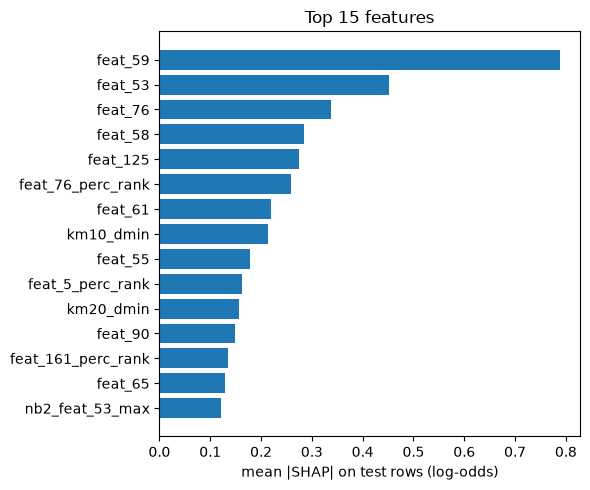

In [16]:
feat_types = {"original features": BASE, "neighbour agg":graph_agg,
              "communities":louvain_comm,"k-means":k_means,"step ranks":[f"{c}_perc_rank" for c in TOP40]}
all_cols = [c for cols in feat_types.values() for c in cols]
model = lgb.LGBMClassifier(**PARAMS, random_state=0)
model.fit(lab[tot_feats].to_numpy(np.float32), lab["label"].to_numpy())
#tree SHAP on test rows
Xt = tst[tot_feats].to_numpy(np.float32)
contrib = model.predict(Xt, pred_contrib=True)# one column per feature + a last bias column
shap_abs = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=tot_feats)
gain = pd.Series(model.booster_.feature_importance("gain"), index=tot_feats)
#share of SHAP and of gain per feat_type
rows = []
for name, cols in feat_types.items():
    rows.append({"featuretype": name,"columns": len(cols),
                 "SHAP share on test": shap_abs[cols].sum()/shap_abs.sum(),"share of gain": gain[cols].sum()/gain.sum()})
display(pd.DataFrame(rows).sort_values("SHAP share on test", ascending=False).round(3))
#top 15 feats by mean |SHAP| on test
top = shap_abs.sort_values(ascending=False).head(15)
plt.figure(figsize=(6, 5))
plt.barh(top.index[::-1], top.values[::-1])
plt.xlabel("mean |SHAP| on test rows (log-odds)")
plt.title("Top 15 features")
plt.tight_layout()
plt.show()